In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

sns.set_style("whitegrid")

In [3]:
DATA_PATH = r"E:\DataMining_Group32\data\raw\group_32_train.csv"

df = pd.read_csv(DATA_PATH)

df.head()

,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,f12,f13,f14,f15,f16,f17,f18,f19,f20,f21,f22,f23,f24,f25,f26,f27,f28,f29,f30,f31,f32,f33,f34,y
0,Source1,2022-07-23 00:36:30.000000000,2022-07-23 00:56:30.000000000,38.945171,-76.863216,-76.876216,0.702,Slow traffic on US-50 W - John Hanson Hwy W fr...,US-50,Hyattsville,MD,US,2022-07-23 00:28:00,83.0,83.0,93.0,10.0,WSW,5.0,0.0,Fair,False,False,False,False,False,False,False,False,False,False,Night,Night,Night,2
1,Source3,2019-09-20 15:04:19,2019-09-20 16:53:35,33.875355,-118.193169,NaN,0.000,Gore point obstructed due to accident on CA-91...,Artesia Fwy E,Long Beach,CA,US,2019-09-20 14:53:00,80.0,80.0,42.0,10.0,SW,12.0,0.0,Fair,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,3
2,Source1,2022-09-19 08:55:00,2022-09-19 09:18:00,29.983199,-90.107440,-90.110599,0.201,Slow traffic on City Park Ave from Orleans Ave...,Conti St,New Orleans,LA,US,2022-09-19 08:55:00,87.0,87.0,67.0,10.0,NE,12.0,0.0,Partly Cloudy,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,2
3,Source2,2016-11-10 08:49:06,2016-11-10 09:18:42,28.019382,-82.746826,NaN,0.010,Accident on FL-580 Main St at Belcher Rd.,Belcher Rd,Clearwater,FL,US,2016-11-10 08:53:00,64.9,NaN,81.0,10.0,NE,8.1,NaN,Clear,False,False,False,False,False,False,False,False,True,False,Day,Day,Day,2
4,Source2,2021-07-05 16:23:08,2021-07-05 16:52:25,35.293308,-119.252258,NaN,0.000,Accident on I-5 Northbound at Exit 246 CA-43.,I-5 N,Bakersfield,CA,US,2021-07-05 15:54:00,99.0,99.0,16.0,9.0,NW,10.0,0.0,Fair,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,2


In [4]:
print("Shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Shape: (100000, 35)
Number of rows: 100000
Number of columns: 35


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 35 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   f1      100000 non-null  object 
 1   f2      100000 non-null  object 
 2   f3      100000 non-null  object 
 3   f4      100000 non-null  float64
 4   f5      100000 non-null  float64
 5   f6      56014 non-null   float64
 6   f7      100000 non-null  float64
 7   f8      100000 non-null  object 
 8   f9      99860 non-null   object 
 9   f10     99998 non-null   object 
 10  f11     100000 non-null  object 
 11  f12     100000 non-null  object 
 12  f13     98455 non-null   object 
 13  f14     97908 non-null   float64
 14  f15     74086 non-null   float64
 15  f16     97766 non-null   float64
 16  f17     97758 non-null   float64
 17  f18     97728 non-null   object 
 18  f19     92515 non-null   float64
 19  f20     71569 non-null   float64
 20  f21     97770 non-null   object 
 21  f22     100

Descriptive Statistics

In [6]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
f1,100000,3,Source1,56014,NaN,NaN,NaN,NaN,NaN,NaN,NaN
f2,100000,99403,2017-05-15 09:22:55,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
f3,100000,99761,2017-05-15 15:22:55,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
f4,100000.0,NaN,NaN,NaN,36.209222,5.083702,24.555269,33.396682,35.841489,40.088354,48.963991
f5,100000.0,NaN,NaN,NaN,-94.651227,17.381554,-124.497357,-117.205811,-87.7473,-80.336987,-67.841889
f6,56014.0,NaN,NaN,NaN,-95.624604,18.106587,-124.497438,-117.743034,-87.952857,-80.234388,-67.842169
f7,100000.0,NaN,NaN,NaN,0.562931,1.756969,0.0,0.0,0.03,0.468,155.186
f8,100000,92530,A crash has occurred causing no to minimum del...,110,NaN,NaN,NaN,NaN,NaN,NaN,NaN
f9,99860,32704,I-95 N,1005,NaN,NaN,NaN,NaN,NaN,NaN,NaN
f10,99998,6433,Miami,2410,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Target Class

In [7]:
df["y"].value_counts()

y
2    79646
3    16795
4     2711
1      848
Name: count, dtype: int64

In [8]:
df["y"].value_counts(normalize=True) * 100

y
2    79.646
3    16.795
4     2.711
1     0.848
Name: proportion, dtype: float64

Class distribution chart

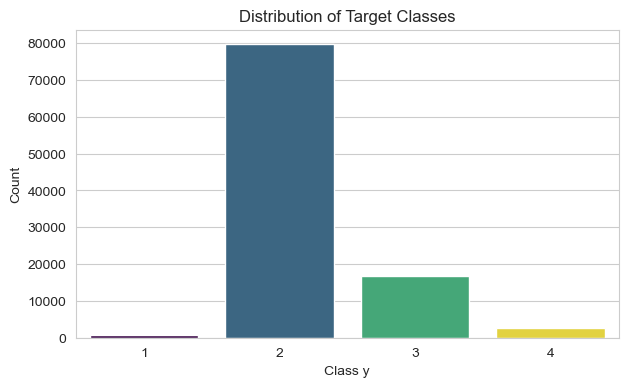

In [10]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="y", hue="y", palette="viridis", legend=False)

plt.title("Distribution of Target Classes")
plt.xlabel("Class y")
plt.ylabel("Count")
plt.show()

missing values

In [11]:
missing_count = df.isnull().sum()
missing_percent = df.isnull().mean() * 100

missing_table = pd.DataFrame({
    "missing_count": missing_count,
    "missing_percent": missing_percent
}).sort_values("missing_percent", ascending=False)

missing_table[missing_table["missing_count"] > 0]

,missing_count,missing_percent
f6,43986,43.986
f20,28431,28.431
f15,25914,25.914
f19,7485,7.485
f18,2272,2.272
f17,2242,2.242
f16,2234,2.234
f21,2230,2.230
f14,2092,2.092
f13,1545,1.545


missing value chart

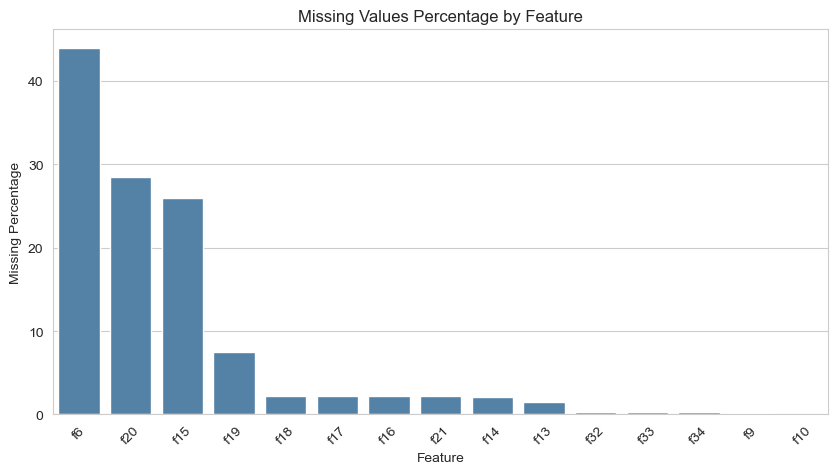

In [13]:
missing_nonzero = missing_table[missing_table["missing_count"] > 0]

plt.figure(figsize=(10, 5))
sns.barplot(
    data=missing_nonzero.reset_index(),
    x="index",
    y="missing_percent",
    color="steelblue"
)

plt.title("Missing Values Percentage by Feature")
plt.xlabel("Feature")
plt.ylabel("Missing Percentage")
plt.xticks(rotation=45)
plt.show()

Duplicates

In [14]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate feature rows without y:", df.drop(columns=["y"]).duplicated().sum())

Duplicate rows: 22
Duplicate feature rows without y: 26


Uniqes

In [15]:
unique_counts = df.nunique().sort_values()
unique_counts

f31        1
f12        1
f33        2
f32        2
f30        2
f29        2
f28        2
f27        2
f26        2
f25        2
f24        2
f23        2
f22        2
f34        2
f1         3
y          4
f18       24
f17       46
f11       49
f19       78
f21       87
f16       99
f20      115
f14      586
f15      649
f7      6139
f10     6433
f9     32704
f6     51776
f13    77867
f4     90706
f5     90742
f8     92530
f2     99403
f3     99761
dtype: int64

Constant Columns

In [16]:
constant_columns = [col for col in df.columns if df[col].nunique(dropna=False) == 1]
constant_columns

['f12', 'f31']

Feature Types

In [17]:
target_col = "y"

numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns.drop(target_col)
categorical_cols = df.select_dtypes(include=["object"]).columns
bool_cols = df.select_dtypes(include=["bool"]).columns

print("Numeric columns:", list(numeric_cols))
print("Categorical columns:", list(categorical_cols))
print("Boolean columns:", list(bool_cols))

Numeric columns: ['f4', 'f5', 'f6', 'f7', 'f14', 'f15', 'f16', 'f17', 'f19', 'f20']
Categorical columns: ['f1', 'f2', 'f3', 'f8', 'f9', 'f10', 'f11', 'f12', 'f13', 'f18', 'f21', 'f32', 'f33', 'f34']
Boolean columns: ['f22', 'f23', 'f24', 'f25', 'f26', 'f27', 'f28', 'f29', 'f30', 'f31']


Numeric columns

In [18]:
df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
f4,100000.0,36.209222,5.083702,24.555269,33.396682,35.841489,40.088354,48.963991
f5,100000.0,-94.651227,17.381554,-124.497357,-117.205811,-87.747300,-80.336987,-67.841889
f6,56014.0,-95.624604,18.106587,-124.497438,-117.743034,-87.952857,-80.234388,-67.842169
f7,100000.0,0.562931,1.756969,0.000000,0.000000,0.030000,0.468000,155.186000
f14,97908.0,61.712058,18.974753,-35.000000,49.000000,64.000000,76.000000,115.000000
f15,74086.0,58.284982,22.327551,-51.300000,43.000000,62.000000,75.000000,115.000000
f16,97766.0,64.856995,22.826354,2.000000,48.000000,67.000000,84.000000,100.000000
f17,97758.0,9.079884,2.624336,0.000000,10.000000,10.000000,10.000000,80.000000
f19,92515.0,7.679091,5.293972,0.000000,4.600000,7.000000,10.400000,190.000000
f20,71569.0,0.008416,0.104839,0.000000,0.000000,0.000000,0.000000,10.000000


Numerical Coulmns Histogram

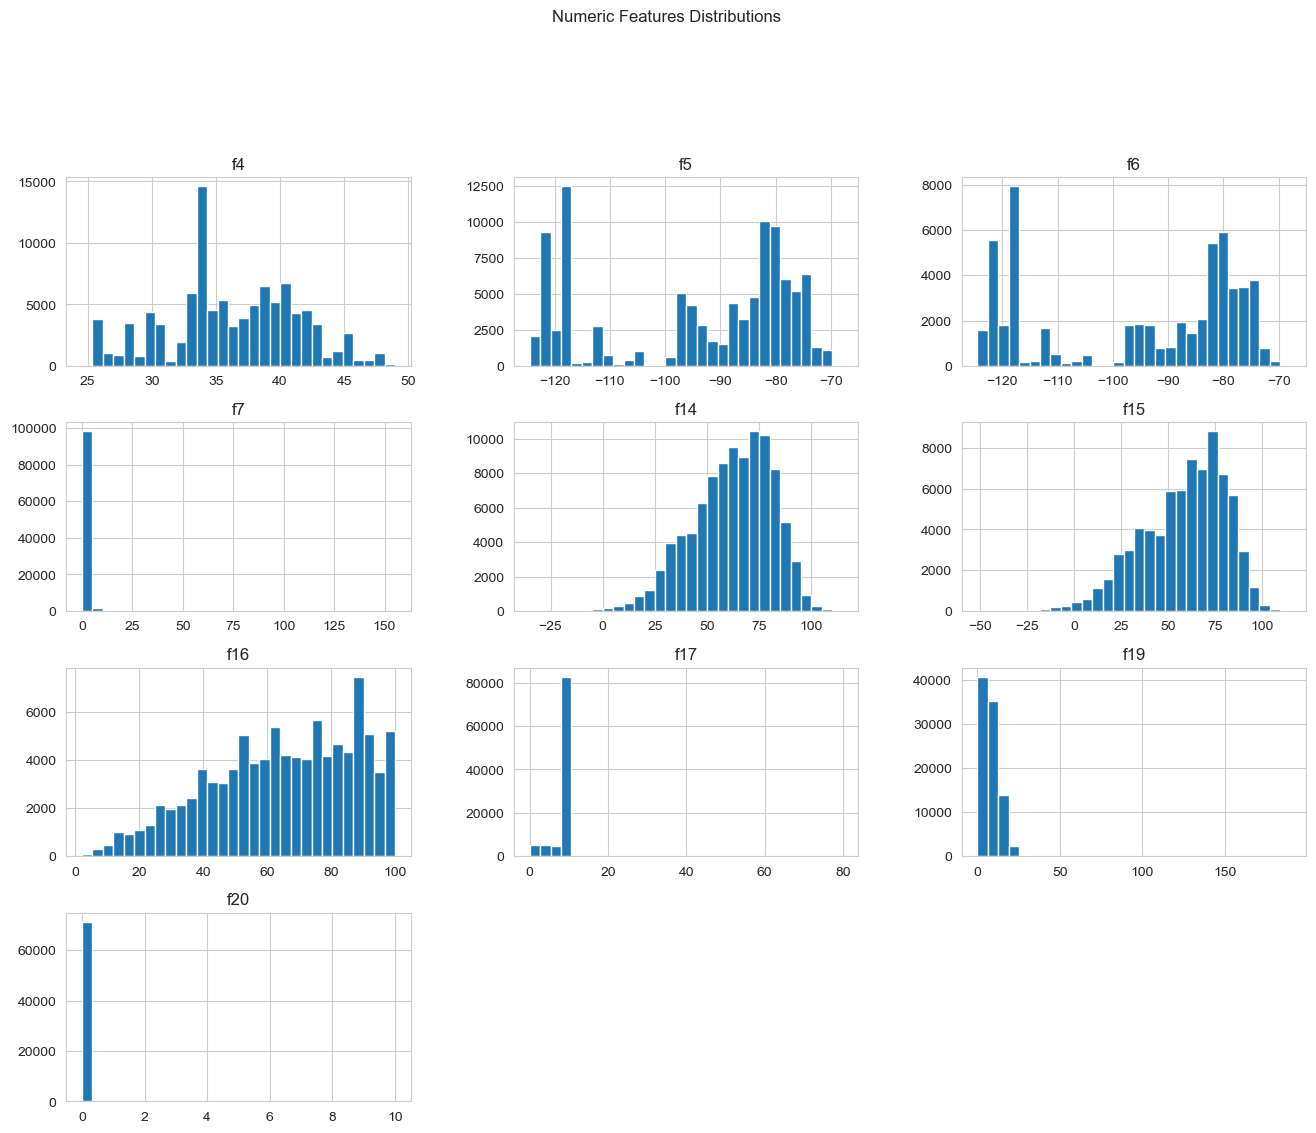

In [19]:
df[numeric_cols].hist(figsize=(16, 12), bins=30)
plt.suptitle("Numeric Features Distributions", y=1.02)
plt.show()

Boolean columns

In [20]:
bool_summary = pd.DataFrame({
    "true_count": df[bool_cols].sum(),
    "true_percent": df[bool_cols].mean() * 100
}).sort_values("true_percent", ascending=False)

bool_summary

,true_count,true_percent
f30,14709,14.709
f23,11335,11.335
f28,2779,2.779
f27,2635,2.635
f22,1259,1.259
f25,871,0.871
f24,267,0.267
f29,111,0.111
f26,4,0.004
f31,0,0.000


In [21]:
for col in categorical_cols:
    print("=" * 50)
    print(col)
    print("Unique values:", df[col].nunique(dropna=True))
    print(df[col].value_counts(dropna=False).head(10))

f1
Unique values: 3
f1
Source1    56014
Source2    42744
Source3     1242
Name: count, dtype: int64
f2
Unique values: 99403
f2
2017-05-15 09:22:55    5
2021-01-26 16:16:13    4
2020-10-16 10:20:00    4
2022-08-18 09:04:00    3
2020-10-21 12:38:30    3
2021-12-24 15:02:30    3
2021-12-16 16:54:40    3
2020-12-12 14:27:00    3
2022-04-26 16:14:30    3
2020-11-14 21:56:00    3
Name: count, dtype: int64
f3
Unique values: 99761
f3
2017-05-15 15:22:55    5
2022-08-18 13:45:00    4
2020-12-24 08:44:00    3
2022-11-21 14:03:48    2
2023-01-06 18:29:10    2
2020-10-25 21:07:14    2
2018-11-21 10:26:38    2
2022-01-16 19:17:09    2
2016-10-26 12:51:48    2
2022-07-02 19:16:31    2
Name: count, dtype: int64
f8
Unique values: 92530
f8
A crash has occurred causing no to minimum delays. Use caution.                                        110
Accident                                                                                                92
An unconfirmed report of a crash has been received. U

In [22]:
df["f2_datetime"] = pd.to_datetime(df["f2"], errors="coerce", format="mixed")
df["f3_datetime"] = pd.to_datetime(df["f3"], errors="coerce", format="mixed")
df["f13_datetime"] = pd.to_datetime(df["f13"], errors="coerce", format="mixed")

df[["f2_datetime", "f3_datetime", "f13_datetime"]].head()

,f2_datetime,f3_datetime,f13_datetime
0,2022-07-23 00:36:30,2022-07-23 00:56:30,2022-07-23 00:28:00
1,2019-09-20 15:04:19,2019-09-20 16:53:35,2019-09-20 14:53:00
2,2022-09-19 08:55:00,2022-09-19 09:18:00,2022-09-19 08:55:00
3,2016-11-10 08:49:06,2016-11-10 09:18:42,2016-11-10 08:53:00
4,2021-07-05 16:23:08,2021-07-05 16:52:25,2021-07-05 15:54:00


Duration Calculation

In [23]:
df["duration_minutes"] = (
    df["f3_datetime"] - df["f2_datetime"]
).dt.total_seconds() / 60

df["duration_minutes"].describe()

count    1.000000e+05
mean     4.594738e+02
std      1.395346e+04
min      2.500000e+00
25%      3.180000e+01
50%      7.476667e+01
75%      1.247667e+02
max      1.576860e+06
Name: duration_minutes, dtype: float64

Duration chart

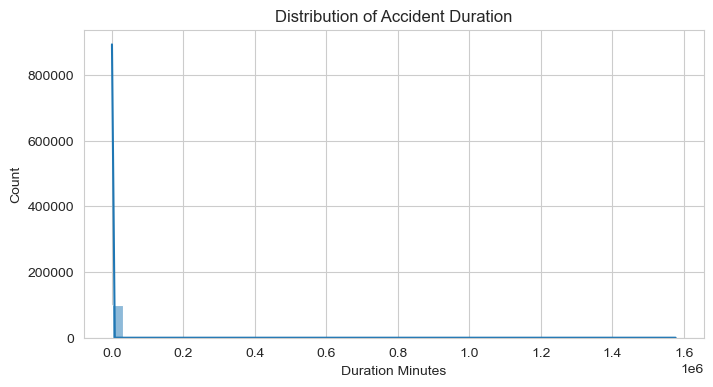

In [28]:
plt.figure(figsize=(8, 4))
sns.histplot(df["duration_minutes"], bins=50, kde=True)

plt.title("Distribution of Accident Duration")
plt.xlabel("Duration Minutes")
plt.ylabel("Count")
plt.show()

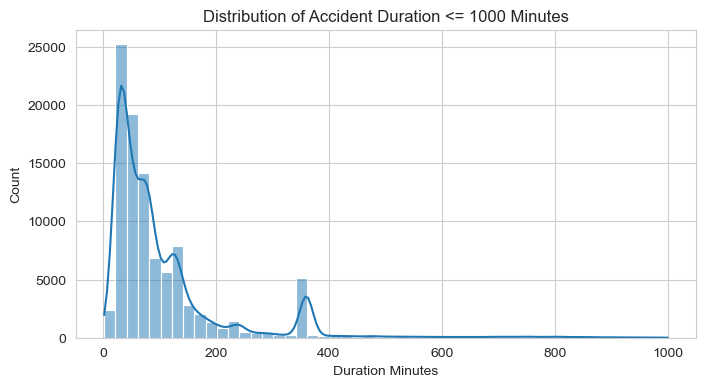

In [29]:
plt.figure(figsize=(8, 4))
sns.histplot(df[df["duration_minutes"] <= 1000]["duration_minutes"], bins=50, kde=True)

plt.title("Distribution of Accident Duration <= 1000 Minutes")
plt.xlabel("Duration Minutes")
plt.ylabel("Count")
plt.show()

In [30]:
df["start_hour"] = df["f2_datetime"].dt.hour
df["start_month"] = df["f2_datetime"].dt.month
df["start_dayofweek"] = df["f2_datetime"].dt.dayofweek

df[["start_hour", "start_month", "start_dayofweek"]].head()

,start_hour,start_month,start_dayofweek
0,0,7,5
1,15,9,4
2,8,9,0
3,8,11,3
4,16,7,0


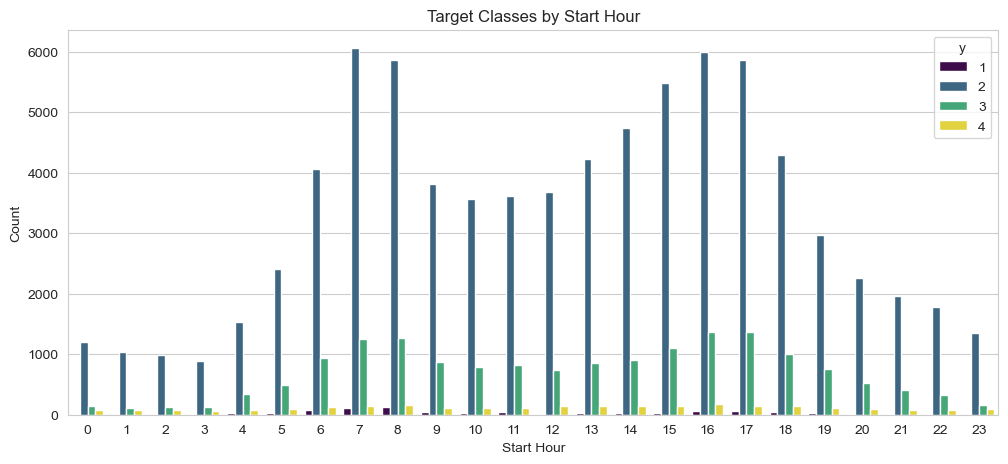

In [31]:
plt.figure(figsize=(12, 5))
sns.countplot(data=df, x="start_hour", hue="y", palette="viridis")

plt.title("Target Classes by Start Hour")
plt.xlabel("Start Hour")
plt.ylabel("Count")
plt.legend(title="y")
plt.show()

In [32]:
pd.crosstab(df["f1"], df["y"], normalize="index") * 100

y,1,2,3,4
f1,,,,
Source1,0.606991,91.057593,3.825829,4.509587
Source2,1.090211,65.190436,33.291222,0.428130
Source3,3.381643,62.479871,33.977456,0.161031


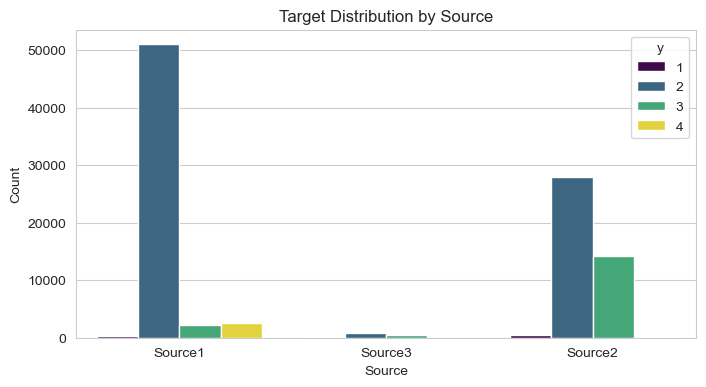

In [33]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="f1", hue="y", palette="viridis")

plt.title("Target Distribution by Source")
plt.xlabel("Source")
plt.ylabel("Count")
plt.legend(title="y")
plt.show()

In [34]:
df["f11"].value_counts().head(15)


f11
CA    22366
FL    11411
TX     7549
SC     4926
NY     4499
NC     4372
VA     3990
PA     3874
MN     2483
OR     2336
IL     2209
AZ     2184
GA     2138
TN     2134
MI     2029
Name: count, dtype: int64

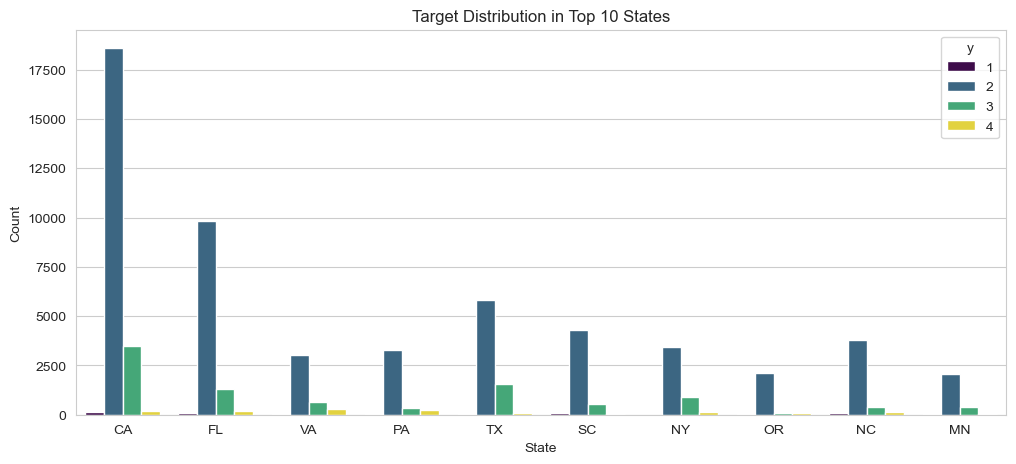

In [35]:
top_states = df["f11"].value_counts().head(10).index

plt.figure(figsize=(12, 5))
sns.countplot(data=df[df["f11"].isin(top_states)], x="f11", hue="y", palette="viridis")

plt.title("Target Distribution in Top 10 States")
plt.xlabel("State")
plt.ylabel("Count")
plt.legend(title="y")
plt.show()

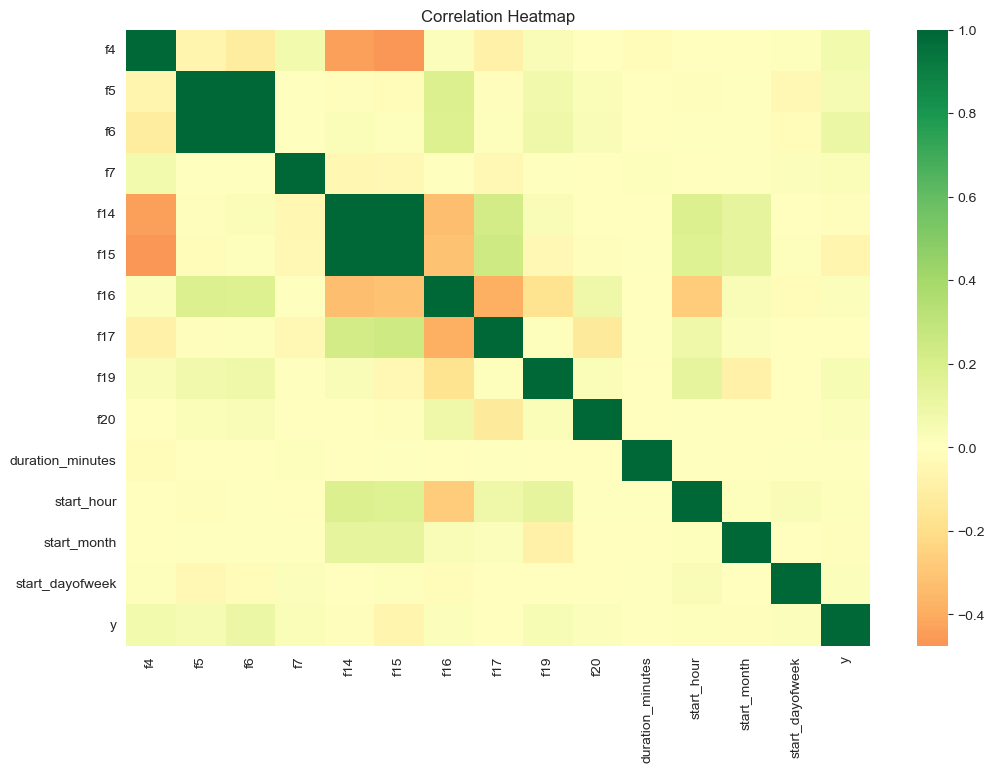

In [39]:
corr_cols = list(numeric_cols) + ["duration_minutes", "start_hour", "start_month", "start_dayofweek", "y"]

plt.figure(figsize=(12, 8))
sns.heatmap(df[corr_cols].corr(), cmap="RdYlGn", center=0)

plt.title("Correlation Heatmap")
plt.show()

In [40]:
eda_summary = {
    "shape": df.shape,
    "target_distribution": df["y"].value_counts().to_dict(),
    "target_distribution_percent": (df["y"].value_counts(normalize=True) * 100).round(2).to_dict(),
    "columns_with_missing": missing_table[missing_table["missing_count"] > 0].to_dict(),
    "constant_columns": constant_columns,
    "duplicate_rows": int(df.duplicated().sum())
}

eda_summary

{'shape': (100000, 42),
 'target_distribution': {2: 79646, 3: 16795, 4: 2711, 1: 848},
 'target_distribution_percent': {2: 79.65, 3: 16.79, 4: 2.71, 1: 0.85},
 'columns_with_missing': {'missing_count': {'f6': 43986,
   'f20': 28431,
   'f15': 25914,
   'f19': 7485,
   'f18': 2272,
   'f17': 2242,
   'f16': 2234,
   'f21': 2230,
   'f14': 2092,
   'f13': 1545,
   'f32': 301,
   'f33': 301,
   'f34': 301,
   'f9': 140,
   'f10': 2},
  'missing_percent': {'f6': 43.986,
   'f20': 28.431,
   'f15': 25.913999999999998,
   'f19': 7.485,
   'f18': 2.2720000000000002,
   'f17': 2.242,
   'f16': 2.234,
   'f21': 2.23,
   'f14': 2.092,
   'f13': 1.545,
   'f32': 0.301,
   'f33': 0.301,
   'f34': 0.301,
   'f9': 0.13999999999999999,
   'f10': 0.002}},
 'constant_columns': ['f12', 'f31'],
 'duplicate_rows': 22}